In [19]:

import requests

print("Requests kütüphanesi hazır!")


Requests kütüphanesi hazır!


In [20]:

# USGS API adresi
url = "https://earthquake.usgs.gov/fdsnws/event/1/query"

# Çekmek istediğimiz verilerin özellikleri
params = {
    "format": "geojson",
    "starttime": "2025-01-01",
    "endtime": "2025-02-01",
    "minmagnitude": 4.5,
    "eventtype": "earthquake",
    "limit": 10
}

# API'ye istek gönderiyoruz
response = requests.get(url, params=params, timeout=30)

# İsteğin başarılı olup olmadığını kontrol ediyoruz
response.raise_for_status()

# Gelen veriyi JSON formatına dönüştürüyoruz
data = response.json()

# Sonuçları ekrana yazdırıyoruz
print("API bağlantısı başarılı!")
print("Çekilen deprem sayısı:", len(data["features"]))

for deprem in data["features"]:
    print(
        deprem["properties"]["place"],
        "- Büyüklük:",
        deprem["properties"]["mag"]
    )


API bağlantısı başarılı!
Çekilen deprem sayısı: 10
74 km WNW of Lata, Solomon Islands - Büyüklük: 4.5
30 km NNE of Attu Station, Alaska - Büyüklük: 4.9
32 km W of Archidona, Ecuador - Büyüklük: 5.5
135 km ENE of Hihifo, Tonga - Büyüklük: 4.7
Banda Sea - Büyüklük: 4.5
138 km ESE of Kirakira, Solomon Islands - Büyüklük: 4.5
Kermadec Islands, New Zealand - Büyüklük: 5
South Sandwich Islands region - Büyüklük: 4.7
145 km E of Kirakira, Solomon Islands - Büyüklük: 5.4
58 km SSE of Blangpidie, Indonesia - Büyüklük: 5.7


In [21]:

import requests
import json
import time
from pathlib import Path

# API adresimiz
url = "https://earthquake.usgs.gov/fdsnws/event/1/query"

# 2025 yılının tüm aylarını tek tek gezeceğiz
all_earthquakes = []

for month in range(1, 13):
    start_date = f"2025-{month:02d}-01"

    if month == 12:
        end_date = "2026-01-01"
    else:
        end_date = f"2025-{month+1:02d}-01"

    params = {
        "format": "geojson",
        "starttime": start_date,
        "endtime": end_date,
        "minmagnitude": 4.5,
        "eventtype": "earthquake",
        "limit": 20000
    }

    response = requests.get(
        url, params=params, timeout=60
    )
    response.raise_for_status()

    data = response.json()
    earthquakes = data["features"]

    all_earthquakes.extend(earthquakes)

    print(f"{month}. ay: {len(earthquakes)} deprem")

    time.sleep(0.3)

# Ayların sınırlarında tekrar eden kayıtları kaldır
unique_earthquakes = {
    eq["id"]: eq for eq in all_earthquakes
}
records = list(unique_earthquakes.values())

# Ham verileri klasöre kaydet
Path("data/raw").mkdir(parents=True, exist_ok=True)

with open("data/raw/earthquakes_2025.json", "w", encoding="utf-8") as f:
    json.dump(records, f, ensure_ascii=False, indent=2)

print("----------------------------")
print("Toplanan kayıt:", len(all_earthquakes))
print("Benzersiz deprem:", len(records))
print("Ham veri dosyası kaydedildi!")


1. ay: 655 deprem
2. ay: 571 deprem
3. ay: 539 deprem
4. ay: 600 deprem
5. ay: 595 deprem
6. ay: 553 deprem
7. ay: 1321 deprem
8. ay: 983 deprem
9. ay: 802 deprem
10. ay: 756 deprem
11. ay: 622 deprem
12. ay: 562 deprem
----------------------------
Toplanan kayıt: 8559
Benzersiz deprem: 8559
Ham veri dosyası kaydedildi!


In [22]:

import pandas as pd
import json

# Kaydettiğimiz JSON dosyasını açıyoruz
with open("data/raw/earthquakes_2025.json", "r", encoding="utf-8") as f:
    records = json.load(f)

# JSON verilerini DataFrame'e dönüştürüyoruz
df = pd.json_normalize(records)

# İlk 5 satırı görüntülüyoruz
df.head()


,type,id,properties.mag,properties.place,properties.time,properties.updated,properties.tz,properties.url,properties.detail,properties.felt,...,properties.types,properties.nst,properties.dmin,properties.rms,properties.gap,properties.magType,properties.type,properties.title,geometry.type,geometry.coordinates
0,Feature,us7000pc44,4.5,"74 km WNW of Lata, Solomon Islands",1738367859481,1744750533040,None,https://earthquake.usgs.gov/earthquakes/eventp...,https://earthquake.usgs.gov/fdsnws/event/1/que...,NaN,...,",origin,phase-data,",18.0,5.237,0.94,139.0,mb,earthquake,"M 4.5 - 74 km WNW of Lata, Solomon Islands",Point,"[165.1584, -10.4839, 49.061]"
1,Feature,us7000pai0,4.9,"30 km NNE of Attu Station, Alaska",1738365571875,1744750526040,None,https://earthquake.usgs.gov/earthquakes/eventp...,https://earthquake.usgs.gov/fdsnws/event/1/que...,NaN,...,",origin,phase-data,shakemap,",115.0,0.560,1.05,85.0,mb,earthquake,"M 4.9 - 30 km NNE of Attu Station, Alaska",Point,"[173.3935, 53.0906, 10]"
2,Feature,us7000pahy,5.5,"32 km W of Archidona, Ecuador",1738364548845,1744750526040,None,https://earthquake.usgs.gov/earthquakes/eventp...,https://earthquake.usgs.gov/fdsnws/event/1/que...,26.0,...,",dyfi,ground-failure,impact-text,internal-mome...",96.0,0.300,0.68,64.0,mww,earthquake,"M 5.5 - 32 km W of Archidona, Ecuador",Point,"[-78.0956, -0.8609, 8]"
3,Feature,us7000pagf,4.7,"135 km ENE of Hihifo, Tonga",1738353008786,1744750526040,None,https://earthquake.usgs.gov/earthquakes/eventp...,https://earthquake.usgs.gov/fdsnws/event/1/que...,NaN,...,",origin,phase-data,",37.0,1.928,0.84,79.0,mb,earthquake,"M 4.7 - 135 km ENE of Hihifo, Tonga",Point,"[-172.5599, -15.6943, 10]"
4,Feature,us7000pafc,4.5,Banda Sea,1738347071331,1744750525040,None,https://earthquake.usgs.gov/earthquakes/eventp...,https://earthquake.usgs.gov/fdsnws/event/1/que...,NaN,...,",origin,phase-data,",80.0,2.210,0.60,49.0,mb,earthquake,M 4.5 - Banda Sea,Point,"[129.8309, -6.7457, 164.158]"


In [23]:

# İhtiyacımız olan sütunları seçiyoruz
df = df[[
    "id",
    "properties.mag",
    "properties.place",
    "properties.time",
    "geometry.coordinates"
]].copy()

# Sütun isimlerini sadeleştiriyoruz
df.columns = [
    "id",
    "magnitude",
    "place",
    "time",
    "coordinates"
]

# Koordinatları ayrı sütunlara ayırıyoruz
df["longitude"] = df["coordinates"].apply(lambda x: x[0])
df["latitude"] = df["coordinates"].apply(lambda x: x[1])
df["depth"] = df["coordinates"].apply(lambda x: x[2])

# Artık gerekmeyen sütunu kaldırıyoruz
df = df.drop(columns=["coordinates"])

# Sonuç
df.head()


,id,magnitude,place,time,longitude,latitude,depth
0,us7000pc44,4.5,"74 km WNW of Lata, Solomon Islands",1738367859481,165.1584,-10.4839,49.061
1,us7000pai0,4.9,"30 km NNE of Attu Station, Alaska",1738365571875,173.3935,53.0906,10.000
2,us7000pahy,5.5,"32 km W of Archidona, Ecuador",1738364548845,-78.0956,-0.8609,8.000
3,us7000pagf,4.7,"135 km ENE of Hihifo, Tonga",1738353008786,-172.5599,-15.6943,10.000
4,us7000pafc,4.5,Banda Sea,1738347071331,129.8309,-6.7457,164.158


In [24]:

print("Toplam deprem sayısı:", df.shape[0])
print("Toplam sütun sayısı:", df.shape[1])

print("\nSütun isimleri:")
print(df.columns.tolist())

print("\nVeri tipleri:")
print(df.dtypes)


Toplam deprem sayısı: 8559
Toplam sütun sayısı: 7

Sütun isimleri:
['id', 'magnitude', 'place', 'time', 'longitude', 'latitude', 'depth']

Veri tipleri:
id            object
magnitude    float64
place         object
time           int64
longitude    float64
latitude     float64
depth        float64
dtype: object


In [25]:

# Her sütundaki eksik değerleri kontrol ediyoruz
print("Eksik değer sayıları:")
print(df.isnull().sum())

# Tekrar eden deprem kayıtlarını kontrol ediyoruz
print("\nTekrar eden deprem sayısı:")
print(df.duplicated(subset="id").sum())

Eksik değer sayıları:
id           0
magnitude    0
place        0
time         0
longitude    0
latitude     0
depth        0
dtype: int64

Tekrar eden deprem sayısı:
0


In [26]:

# Zaman bilgisini tarih formatına dönüştürüyoruz
df["time"] = pd.to_datetime(
    df["time"],
    unit="ms",
    utc=True
)

# Tarihten yıl ve ay bilgilerini çıkarıyoruz
df["year"] = df["time"].dt.year
df["month"] = df["time"].dt.month

# İlk 5 depremi görüntülüyoruz
df[["time", "year", "month", "magnitude"]].head()



,time,year,month,magnitude
0,2025-01-31 23:57:39.481000+00:00,2025,1,4.5
1,2025-01-31 23:19:31.875000+00:00,2025,1,4.9
2,2025-01-31 23:02:28.845000+00:00,2025,1,5.5
3,2025-01-31 19:50:08.786000+00:00,2025,1,4.7
4,2025-01-31 18:11:11.331000+00:00,2025,1,4.5


In [27]:

# Sayısal sütunlarımızın istatistiklerini inceleyelim
print("Sayısal verilerin özeti:")
print(df[["magnitude", "depth", "latitude", "longitude"]].describe())

# Koordinatları kontrol edelim
print("\nGeçersiz enlem sayısı:")
print((~df["latitude"].between(-90, 90)).sum())

print("\nGeçersiz boylam sayısı:")
print((~df["longitude"].between(-180, 180)).sum())

# 4.5 büyüklüğünden küçük kayıtları kontrol edelim
print("\n4.5'ten küçük deprem sayısı:")
print((df["magnitude"] < 4.5).sum())

# Negatif derinlikleri kontrol edelim
print("\nNegatif derinlikli deprem sayısı:")
print((df["depth"] < 0).sum())

Sayısal verilerin özeti:
         magnitude        depth     latitude    longitude
count  8559.000000  8559.000000  8559.000000  8559.000000
mean      4.809978    53.238969    10.482827    65.496403
std       0.369230    98.451538    33.907034   113.983650
min       4.500000     1.181000   -73.220400  -179.994400
25%       4.500000    10.000000   -14.888050   -27.175550
50%       4.700000    10.000000     9.034000   126.327900
75%       4.900000    51.354000    44.540200   157.295750
max       8.800000   669.556000    87.081500   179.988400

Geçersiz enlem sayısı:
0

Geçersiz boylam sayısı:
0

4.5'ten küçük deprem sayısı:
0

Negatif derinlikli deprem sayısı:
0


In [28]:

from pathlib import Path

# Temizlenmiş verilerin klasörünü oluşturuyoruz
Path("data/processed").mkdir(
    parents=True,
    exist_ok=True
)

# DataFrame'i CSV dosyasına kaydediyoruz
df.to_csv(
    "data/processed/earthquakes_2025_clean.csv",
    index=False
)

print("Temiz veri seti başarıyla kaydedildi!")
print("Toplam satır:", df.shape[0])
print("Toplam sütun:", df.shape[1])



Temiz veri seti başarıyla kaydedildi!
Toplam satır: 8559
Toplam sütun: 9


In [29]:

# Her ay meydana gelen deprem sayısını hesaplıyoruz
monthly_counts = df["month"].value_counts().sort_index()

# Sonuçları ekrana yazdırıyoruz
print("2025 Yılı Aylık Deprem Sayıları:")
print(monthly_counts)


2025 Yılı Aylık Deprem Sayıları:
month
1      655
2      571
3      539
4      600
5      595
6      553
7     1321
8      983
9      802
10     756
11     622
12     562
Name: count, dtype: int64


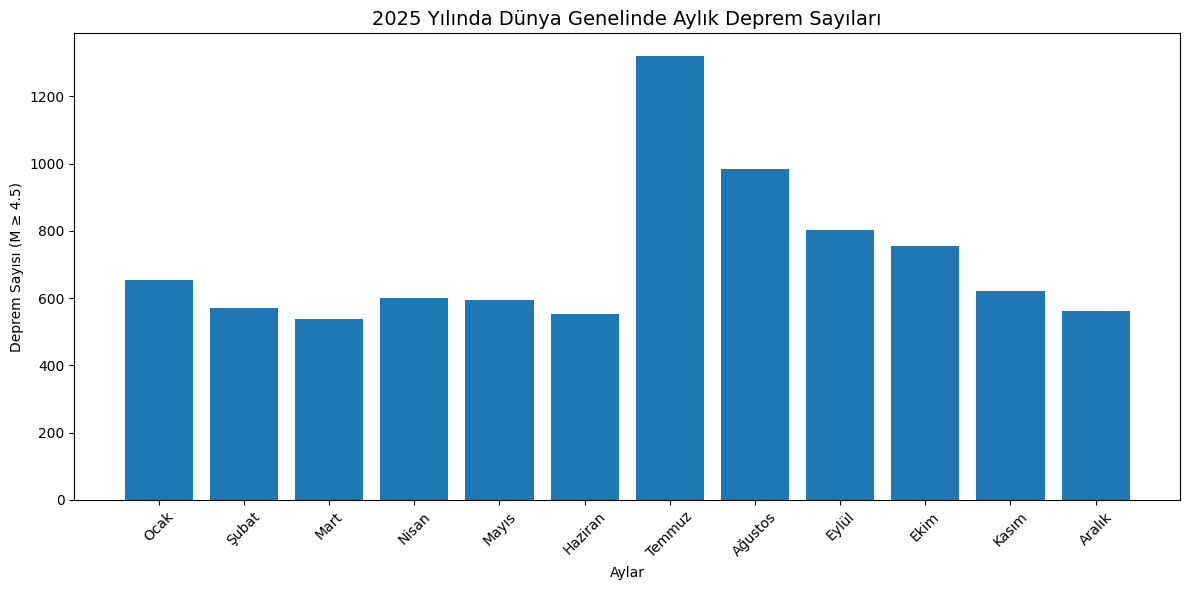

In [30]:

import matplotlib.pyplot as plt

# Ay isimlerini belirliyoruz
months = [
    "Ocak", "Şubat", "Mart", "Nisan",
    "Mayıs", "Haziran", "Temmuz", "Ağustos",
    "Eylül", "Ekim", "Kasım", "Aralık"
]

# Eksik ay varsa sıfırla tamamlıyoruz
monthly_counts = monthly_counts.reindex(
    range(1, 13), fill_value=0
)

# Grafik alanını oluşturuyoruz
plt.figure(figsize=(12, 6))

# Sütun grafiğini çiziyoruz
plt.bar(months, monthly_counts)

# Grafik başlığı ve eksen isimleri
plt.title(
    "2025 Yılında Dünya Genelinde Aylık Deprem Sayıları",
    fontsize=14
)
plt.xlabel("Aylar")
plt.ylabel("Deprem Sayısı (M ≥ 4.5)")

# Ay isimleri üst üste binmesin
plt.xticks(rotation=45)

# Grafiği düzenliyoruz
plt.tight_layout()

from pathlib import Path

Path("figures").mkdir(exist_ok=True)

plt.savefig(
    "figures/monthly_earthquakes_2025.png",
    dpi=300,
    bbox_inches="tight"
)


# Grafiği gösteriyoruz
plt.show()



In [31]:

# Türkçe ay isimleri
months = [
    "Ocak", "Şubat", "Mart", "Nisan",
    "Mayıs", "Haziran", "Temmuz", "Ağustos",
    "Eylül", "Ekim", "Kasım", "Aralık"
]

# Aylık deprem sayılarını hesaplıyoruz
monthly_counts = df["month"].value_counts().reindex(
    range(1, 13), fill_value=0
)

# En fazla ve en az deprem gerçekleşen aylar
max_month = monthly_counts.idxmax()
min_month = monthly_counts.idxmin()

print("En fazla deprem gerçekleşen ay:")
print(months[max_month - 1], "-", monthly_counts[max_month])

print("\nEn az deprem gerçekleşen ay:")
print(months[min_month - 1], "-", monthly_counts[min_month])

print("\nAylık ortalama deprem sayısı:")
print(round(monthly_counts.mean(), 2))


En fazla deprem gerçekleşen ay:
Temmuz - 1321

En az deprem gerçekleşen ay:
Mart - 539

Aylık ortalama deprem sayısı:
713.25


### Araştırma Sorusu 1: Depremlerin Aylara Göre Dağılımı

2025 yılında dünya genelinde meydana gelen 4.5 ve üzeri büyüklükteki 8.559 deprem incelenmiştir.

Analiz sonucunda, en fazla depremin **1.321 kayıt ile temmuz ayında**, en az depremin ise **539 kayıt ile mart ayında** gerçekleştiği belirlenmiştir. Aylık ortalama deprem sayısı 713,25 olarak hesaplanmıştır.

Temmuz ayında kaydedilen deprem sayısı, mart ayından 782 daha fazladır. Bu durum, incelenen yıl içerisinde deprem sayılarının aylara göre önemli farklılıklar gösterdiğini ortaya koymaktadır.

Ancak bu farklılığın mevsimsel bir eğilim olduğunu söylemek için birden fazla yılın incelenmesi gerekmektedir.

In [32]:

# Deprem büyüklüğü ile derinlik arasındaki ilişki
correlation = df["magnitude"].corr(df["depth"])

print("Büyüklük ve derinlik arasındaki korelasyon:")
print(round(correlation, 4))


Büyüklük ve derinlik arasındaki korelasyon:
-0.046


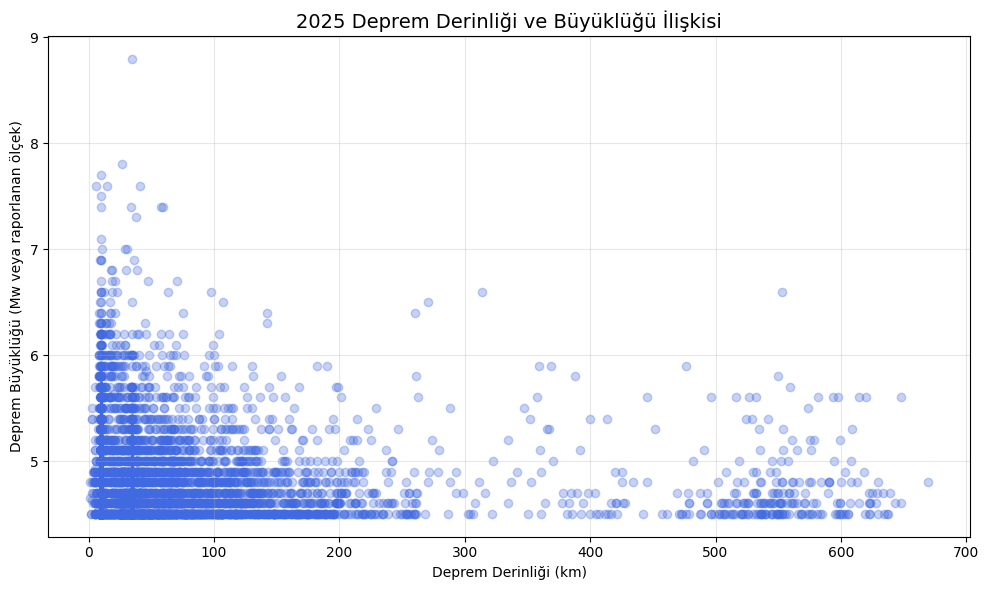

In [33]:

import matplotlib.pyplot as plt
from pathlib import Path

# Grafik alanını oluşturuyoruz
plt.figure(figsize=(10, 6))

# Saçılım grafiği
plt.scatter(
    df["depth"],
    df["magnitude"],
    alpha=0.3,
    color="royalblue"
)

# Başlık ve eksen isimleri
plt.title(
    "2025 Deprem Derinliği ve Büyüklüğü İlişkisi",
    fontsize=14
)
plt.xlabel("Deprem Derinliği (km)")
plt.ylabel("Deprem Büyüklüğü (Mw veya raporlanan ölçek)")

# Izgara ekliyoruz
plt.grid(True, alpha=0.3)

# Grafiği kaydediyoruz
Path("figures").mkdir(exist_ok=True)

plt.tight_layout()
plt.savefig(
    "figures/depth_magnitude_scatter.png",
    dpi=300,
    bbox_inches="tight"
)

# Grafiği gösteriyoruz
plt.show()


### Araştırma Sorusu 2: Deprem Büyüklüğü ile Derinlik Arasındaki İlişki

2025 yılında dünya genelinde gerçekleşen 4.5 ve üzeri büyüklükteki 8.559 deprem incelenmiştir.

Deprem büyüklüğü ile derinliği arasındaki Pearson korelasyon katsayısı **-0.046** olarak hesaplanmıştır.

Bu değer, iki değişken arasında çok zayıf negatif doğrusal ilişki bulunduğunu göstermektedir.

Saçılım grafiğinde depremlerin büyük bölümünün sığ derinliklerde yoğunlaştığı gözlemlenmiştir. Ancak deprem derinliği arttıkça büyüklüğün düzenli biçimde arttığı veya azaldığı görülmemektedir.

**Sonuç:** İncelenen veri setinde deprem büyüklüğü ile derinliği arasında belirgin bir doğrusal ilişki tespit edilmemiştir.

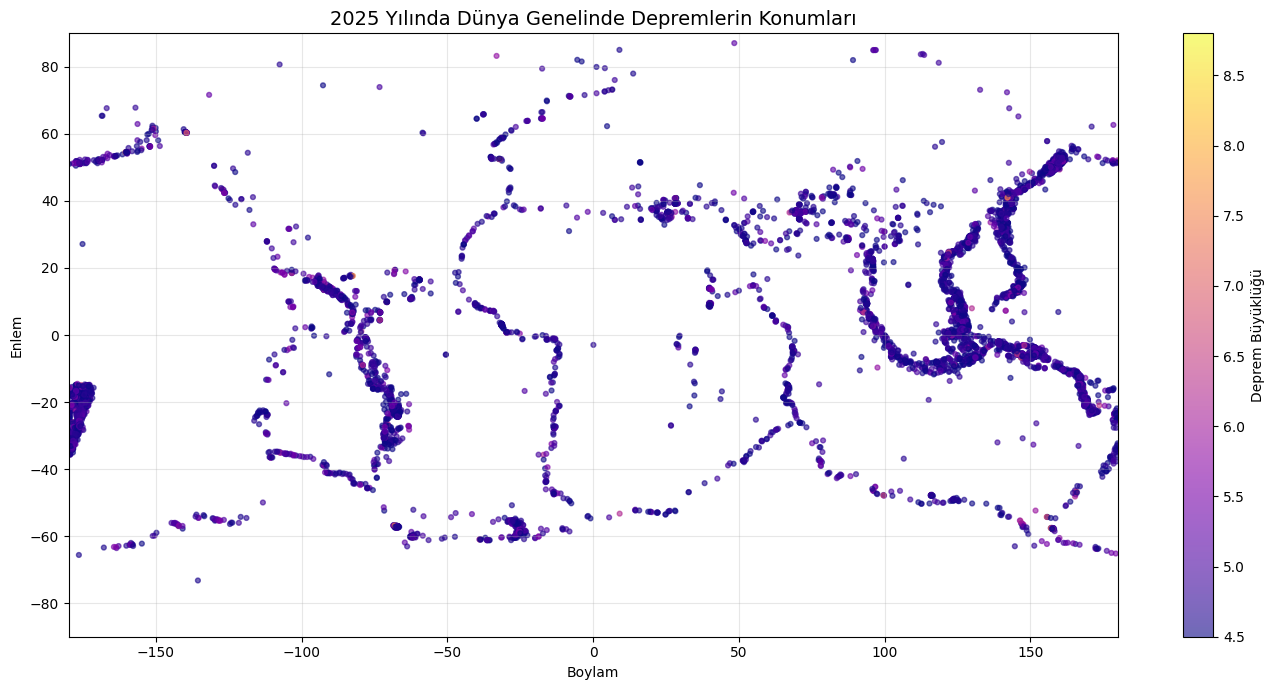

In [34]:

import matplotlib.pyplot as plt
from pathlib import Path

# Grafik alanını oluşturuyoruz
plt.figure(figsize=(14, 7))

# Depremlerin coğrafi konumları
plt.scatter(
    df["longitude"],
    df["latitude"],
    c=df["magnitude"],
    cmap="plasma",
    s=12,
    alpha=0.6
)

# Renk skalası
plt.colorbar(label="Deprem Büyüklüğü")

# Başlık ve eksenler
plt.title(
    "2025 Yılında Dünya Genelinde Depremlerin Konumları",
    fontsize=14
)
plt.xlabel("Boylam")
plt.ylabel("Enlem")

plt.xlim(-180, 180)
plt.ylim(-90, 90)
plt.grid(True, alpha=0.3)

# Grafiği kaydediyoruz
Path("figures").mkdir(exist_ok=True)

plt.tight_layout()
plt.savefig(
    "figures/earthquake_locations_2025.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



### Araştırma Sorusu 3: Depremlerin Coğrafi Dağılımı

2025 yılında dünya genelinde meydana gelen 4.5 ve üzeri büyüklükteki 8.559 depremin enlem ve boylam bilgileri kullanılarak coğrafi dağılımı incelenmiştir.

Görselleştirme sonucunda depremlerin dünya üzerinde homojen biçimde dağılmadığı, belirli tektonik kuşaklarda yoğunlaştığı gözlemlenmiştir.

Özellikle Japonya, Endonezya, Alaska ve Güney Amerika'nın batı kıyılarında deprem kümelenmeleri dikkat çekmektedir.

Bu dağılım, depremlerin önemli bir bölümünün tektonik levha sınırları boyunca meydana gelmesiyle uyumludur.

**Sonuç:** İncelenen veri setinde depremler belirli coğrafi kuşaklarda yoğunlaşmaktadır. Özellikle Pasifik Okyanusu çevresindeki tektonik bölgeler belirgin deprem yoğunluğu göstermektedir.

In [35]:

from pathlib import Path

readme = """# Global Earthquake Data Analysis

## Proje Amacı
Bu projede, 2025 yılında dünya genelinde meydana gelen
4.5 ve üzeri büyüklükteki depremler analiz edilmiştir.

Veriler USGS Earthquake API üzerinden Python kullanılarak
toplanmış, temizlenmiş ve görselleştirilmiştir.

## Veri Kaynağı
- API: USGS Earthquake API
- Kaynak: https://earthquake.usgs.gov/
- Dönem: 01.01.2025 - 31.12.2025
- Deprem sayısı: 8.559
- Minimum büyüklük: 4.5
- Kullanılan alanlar: ID, büyüklük, konum, zaman,
  enlem, boylam ve derinlik

## Araştırma Soruları
1. Depremler aylara göre nasıl dağılıyor?
2. Büyüklük ile derinlik arasında ilişki var mı?
3. Depremler hangi coğrafi bölgelerde yoğunlaşıyor?

## Yöntem
1. USGS API'den aylık sorgularla veriler toplandı.
2. Ham veriler JSON formatında kaydedildi.
3. JSON verileri pandas DataFrame'e dönüştürüldü.
4. Eksik değerler ve tekrar eden kayıtlar kontrol edildi.
5. Tarih alanı düzenlendi.
6. Koordinat ve büyüklük değerleri kontrol edildi.
7. Temiz veri CSV formatında kaydedildi.
8. Matplotlib kullanılarak grafikler oluşturuldu.

## Bulgular

### Aylık Deprem Dağılımı
En fazla deprem temmuz ayında (1.321),
en az deprem mart ayında (539) gerçekleşmiştir.
Aylık ortalama deprem sayısı 713,25'tir.

### Derinlik ve Büyüklük İlişkisi
Pearson korelasyon katsayısı -0.046 bulunmuştur.
İki değişken arasında belirgin doğrusal ilişki
gözlemlenmemiştir.

### Coğrafi Dağılım
Depremler dünya üzerinde homojen dağılmamaktadır.
Japonya, Endonezya, Alaska ve Güney Amerika'nın
batı kıyılarında yoğunlaşmalar görülmektedir.

## Sınırlılıklar
- Yalnızca 2025 yılı incelenmiştir.
- Sadece 4.5 ve üzeri büyüklükteki depremler alınmıştır.
- Sonuçlar farklı yıllar için genellenemez.
- USGS kayıtları sonradan güncellenebilir.
- Coğrafi yoğunluklar görsel olarak değerlendirilmiştir.

## Kullanılan Teknolojiler
- Python
- Google Colab
- requests
- pandas
- Matplotlib
- USGS Earthquake API

## Çalıştırma
1. requirements.txt dosyasındaki paketleri yükleyin.
2. notebooks klasöründeki notebook'u açın.
3. Kod hücrelerini sırasıyla çalıştırın.
4. Ham ve işlenmiş veriler data klasöründe oluşturulur.
5. Grafikler figures klasörüne kaydedilir.
"""

Path("README.md").write_text(readme, encoding="utf-8")

print("README.md dosyası oluşturuldu!")


README.md dosyası oluşturuldu!


In [36]:

from pathlib import Path

requirements = """requests
pandas
matplotlib
"""

Path("requirements.txt").write_text(
    requirements,
    encoding="utf-8"
)

print("requirements.txt dosyası oluşturuldu!")



requirements.txt dosyası oluşturuldu!
